
# RAG Retrieval Evaluation Framework
### Dense vs. Sparse (BM25) vs. Hybrid vs. Graph-based Retrieval

This notebook builds a **benchmarking pipeline** that compares four retrieval
strategies for Retrieval-Augmented Generation (RAG):

| Strategy | How it works |
|---|---|
| **BM25 (sparse)** | Classic lexical/keyword retrieval (Okapi BM25) |
| **Dense** | Embedding similarity search (bi-encoder + vector index) |
| **Hybrid** | Reciprocal Rank Fusion of BM25 + Dense results |
| **GraphRAG** | Entity-graph traversal retrieval (NetworkX, Neo4j-ready) |

Each strategy is scored on:
- **Faithfulness** — is the generated answer actually supported by the retrieved context?
- **Answer Relevancy** — does the answer address the question?
- **Context Precision/Recall** — how good is the retrieved context itself?
- **Latency** — end-to-end retrieval time (ms)

The notebook is **network-resilient by design**: every external dependency
(HuggingFace model downloads, the `datasets` hub, an LLM API key, a running
Neo4j instance, the `ragas` package) is wrapped in a `try/except` with a
sensible offline fallback, so the whole pipeline runs end-to-end even with
no internet access or API keys — and automatically upgrades to the "real"
component the moment that dependency is available.

**To get the full-fidelity results** (true E5 embeddings, a real HotpotQA
sample, LLM-generated answers, and true RAGAS metrics), just run this in an
environment with internet access and set one of `ANTHROPIC_API_KEY` /
`OPENAI_API_KEY` before running Section 6.



## 1. Setup

Install dependencies. Heavy/optional packages (`sentence-transformers`,
`faiss-cpu`, `datasets`, `ragas`, `langchain`, `neo4j`, `anthropic`,
`openai`) are installed **best-effort** — if `pip install` fails (e.g. no
internet in this sandbox), the notebook detects the missing package later
and switches to its fallback implementation automatically.


In [1]:
import sys, subprocess

REQUIRED = ["rank_bm25", "networkx", "scikit-learn", "pandas", "matplotlib", "numpy"]
OPTIONAL = [
    "sentence-transformers",   # dense embeddings (E5)
    "faiss-cpu",               # vector index
    "datasets",                # HuggingFace datasets (Natural Questions / HotpotQA)
    "ragas",                   # RAG evaluation metrics
    "langchain",                # optional glue / loaders
    "langchain-community",
    "neo4j",                   # optional real graph DB backend
    "anthropic",                # Claude API for answer generation
    "openai",                   # optional alternative LLM
]

def pip_install(pkgs):
    try:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", "--break-system-packages", *pkgs],
            check=True, timeout=600,
        )
        return True
    except Exception as e:
        print(f"[setup] could not install {pkgs}: {e}")
        return False

pip_install(REQUIRED)
for pkg in OPTIONAL:
    pip_install([pkg])

print("Setup pass complete. Availability is (re)checked per-component below.")


Setup pass complete. Availability is (re)checked per-component below.



## 2. Imports & Feature Detection

We probe for each optional dependency once and store a boolean flag. Every
later section reads these flags to decide "real" vs "fallback" mode, and
prints which mode it ended up in — so the final report is always honest
about what actually ran.


In [2]:

import os, time, json, math, random, textwrap
from collections import defaultdict
from dataclasses import dataclass, field
from typing import List, Dict, Any, Callable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

random.seed(42)
np.random.seed(42)

FLAGS = {}

try:
    from sentence_transformers import SentenceTransformer
    FLAGS["sentence_transformers"] = True
except Exception:
    FLAGS["sentence_transformers"] = False

try:
    import faiss
    FLAGS["faiss"] = True
except Exception:
    FLAGS["faiss"] = False

try:
    from datasets import load_dataset
    FLAGS["hf_datasets"] = True
except Exception:
    FLAGS["hf_datasets"] = False

try:
    import ragas
    FLAGS["ragas"] = True
except Exception:
    FLAGS["ragas"] = False

try:
    import anthropic
    FLAGS["anthropic"] = True
except Exception:
    FLAGS["anthropic"] = False

try:
    import openai
    FLAGS["openai"] = True
except Exception:
    FLAGS["openai"] = False

try:
    from neo4j import GraphDatabase
    FLAGS["neo4j"] = True
except Exception:
    FLAGS["neo4j"] = False

FLAGS["anthropic_key"] = bool(os.environ.get("ANTHROPIC_API_KEY"))
FLAGS["openai_key"] = bool(os.environ.get("OPENAI_API_KEY"))
FLAGS["neo4j_uri"] = bool(os.environ.get("NEO4J_URI"))

print("Feature availability:")
for k, v in FLAGS.items():
    print(f"  {k:22s}: {v}")


Feature availability:
  sentence_transformers : True
  faiss                 : True
  hf_datasets           : True
  ragas                 : False
  anthropic             : True
  openai                : True
  neo4j                 : True
  anthropic_key         : False
  openai_key            : False
  neo4j_uri             : False



## 3. Dataset

By default this tries to pull a real sample from **HotpotQA** (multi-hop,
good for testing GraphRAG) via the HuggingFace `datasets` hub:

```python
load_dataset("hotpot_qa", "distractor", split="validation[:50]")
```

You can swap this for **Natural Questions** the same way:

```python
load_dataset("natural_questions", split="validation[:50]")
```

or point `HOTPOT_JSON_URL` / `NQ_JSON_URL` below at the official mirrors:

- Natural Questions: https://ai.google.com/research/NaturalQuestions/
- HotpotQA: https://hotpotqa.github.io/

If neither the hub nor a direct URL is reachable (no internet, firewalled
sandbox, etc.), we fall back to a small **bundled sample** of 15 hand-built
multi-hop QA items in the same shape (`question`, `answer`, `context`
passages with titles+sentences, `supporting_facts`) so every downstream
cell still has real data to run against.


In [3]:

HOTPOT_JSON_URL = "https://raw.githubusercontent.com/hotpotqa/hotpotqa.github.io/master/data/hotpot_dev_distractor_sample.json"  # example mirror; replace with a real raw URL if you have one
N_SAMPLES = 15

def _bundled_sample():
    '''15 original hand-authored multi-hop QA items (question / gold answer /
    multiple titled passages, one of which is the 'gold' supporting passage(s)).
    Shaped like HotpotQA so the rest of the pipeline is dataset-agnostic.'''
    return [
        {
            "id": "q1",
            "question": "What ocean borders the country where the Eiffel Tower is located?",
            "answer": "Atlantic Ocean",
            "context": [
                ("Eiffel Tower", ["The Eiffel Tower is a wrought-iron lattice tower in Paris, France.",
                                    "It was designed by Gustave Eiffel's company and completed in 1889."]),
                ("France", ["France is a country in Western Europe.",
                             "Its western coastline borders the Atlantic Ocean.",
                             "France also borders the Mediterranean Sea to the south."]),
                ("Gustave Eiffel", ["Gustave Eiffel was a French civil engineer.",
                                      "He is known for the Eiffel Tower and the Statue of Liberty's frame."]),
            ],
            "supporting_titles": ["Eiffel Tower", "France"],
        },
        {
            "id": "q2",
            "question": "In which city is the university that Alan Turing attended as an undergraduate located?",
            "answer": "Cambridge",
            "context": [
                ("Alan Turing", ["Alan Turing was a British mathematician and computer scientist.",
                                   "He studied as an undergraduate at King's College, Cambridge."]),
                ("King's College, Cambridge", ["King's College is a constituent college of the University of Cambridge.",
                                                  "It is located in Cambridge, England."]),
                ("Bletchley Park", ["Bletchley Park was the site of British codebreaking during WWII.",
                                       "Turing worked there on breaking the Enigma cipher."]),
            ],
            "supporting_titles": ["Alan Turing", "King's College, Cambridge"],
        },
        {
            "id": "q3",
            "question": "What is the capital of the country where Mount Kilimanjaro is located?",
            "answer": "Dodoma",
            "context": [
                ("Mount Kilimanjaro", ["Mount Kilimanjaro is the highest mountain in Africa.",
                                          "It is located in Tanzania, near the border with Kenya."]),
                ("Tanzania", ["Tanzania is a country in East Africa.",
                                "Its official capital is Dodoma, though Dar es Salaam is the largest city."]),
                ("Kenya", ["Kenya is a country in East Africa bordering Tanzania.",
                             "Its capital is Nairobi."]),
            ],
            "supporting_titles": ["Mount Kilimanjaro", "Tanzania"],
        },
        {
            "id": "q4",
            "question": "Who directed the film that won the Academy Award for Best Picture in 1994?",
            "answer": "Steven Spielberg",
            "context": [
                ("Schindler's List", ["Schindler's List is a 1993 American film about the Holocaust.",
                                          "It won the Academy Award for Best Picture at the 1994 ceremony.",
                                          "The film was directed by Steven Spielberg."]),
                ("Steven Spielberg", ["Steven Spielberg is an American film director and producer.",
                                         "He has directed many acclaimed films including Jaws and E.T."]),
                ("Forrest Gump", ["Forrest Gump is a 1994 American film directed by Robert Zemeckis.",
                                     "It won the Academy Award for Best Picture at the 1995 ceremony."]),
            ],
            "supporting_titles": ["Schindler's List", "Steven Spielberg"],
        },
        {
            "id": "q5",
            "question": "What language is primarily spoken in the country where the Colosseum is located?",
            "answer": "Italian",
            "context": [
                ("Colosseum", ["The Colosseum is an ancient amphitheater in Rome, Italy.",
                                  "Construction began under Emperor Vespasian around 70-72 AD."]),
                ("Italy", ["Italy is a country in Southern Europe.",
                             "Italian is the official and primary spoken language."]),
                ("Vespasian", ["Vespasian was a Roman emperor who founded the Flavian dynasty.",
                                  "He began construction of the Colosseum in Rome."]),
            ],
            "supporting_titles": ["Colosseum", "Italy"],
        },
        {
            "id": "q6",
            "question": "What company developed the programming language used to build Android apps natively before Kotlin became preferred?",
            "answer": "Sun Microsystems (Java)",
            "context": [
                ("Android (operating system)", ["Android is a mobile operating system developed by Google.",
                                                    "Native Android apps were traditionally written in Java, later Kotlin."]),
                ("Java (programming language)", ["Java is a general-purpose programming language.",
                                                     "It was originally developed by Sun Microsystems in the mid-1990s."]),
                ("Kotlin", ["Kotlin is a statically typed programming language.",
                              "It was developed by JetBrains and became Google's preferred language for Android in 2019."]),
            ],
            "supporting_titles": ["Android (operating system)", "Java (programming language)"],
        },
        {
            "id": "q7",
            "question": "What river runs through the city that hosts the annual Oktoberfest festival?",
            "answer": "Isar",
            "context": [
                ("Oktoberfest", ["Oktoberfest is the world's largest beer festival, held annually in Munich, Germany.",
                                    "It runs from mid/late September to the first Sunday in October."]),
                ("Munich", ["Munich is the capital of the German state of Bavaria.",
                              "The Isar river flows through the city."]),
                ("Bavaria", ["Bavaria is the largest German state by area.",
                                "Its capital is Munich."]),
            ],
            "supporting_titles": ["Oktoberfest", "Munich"],
        },
        {
            "id": "q8",
            "question": "Which continent is home to the country with the largest population as of the early 2020s?",
            "answer": "Asia",
            "context": [
                ("Demographics of India", ["India surpassed China as the world's most populous country around 2023.",
                                              "India is located in South Asia."]),
                ("Asia", ["Asia is the largest and most populous continent.",
                            "It includes countries such as India, China, and Japan."]),
                ("China", ["China was the world's most populous country for decades before India.",
                              "China is located in East Asia."]),
            ],
            "supporting_titles": ["Demographics of India", "Asia"],
        },
        {
            "id": "q9",
            "question": "What is the native currency of the country where the Great Barrier Reef is located?",
            "answer": "Australian Dollar",
            "context": [
                ("Great Barrier Reef", ["The Great Barrier Reef is the world's largest coral reef system.",
                                           "It is located off the coast of Queensland, Australia."]),
                ("Australia", ["Australia is a country and continent in the Southern Hemisphere.",
                                  "Its official currency is the Australian Dollar."]),
                ("Queensland", ["Queensland is a state in northeastern Australia.",
                                   "It is home to the Great Barrier Reef."]),
            ],
            "supporting_titles": ["Great Barrier Reef", "Australia"],
        },
        {
            "id": "q10",
            "question": "Who composed the music for the ballet that premiered in Paris in 1913 and caused a riot?",
            "answer": "Igor Stravinsky",
            "context": [
                ("The Rite of Spring", ["The Rite of Spring is a ballet and orchestral concert work.",
                                           "Its premiere in Paris in 1913 famously caused a near-riot.",
                                           "The music was composed by Igor Stravinsky."]),
                ("Igor Stravinsky", ["Igor Stravinsky was a Russian-born composer.",
                                        "He is widely considered one of the most influential composers of the 20th century."]),
                ("Ballets Russes", ["Ballets Russes was an itinerant ballet company.",
                                       "It premiered many landmark early 20th-century ballets in Paris."]),
            ],
            "supporting_titles": ["The Rite of Spring", "Igor Stravinsky"],
        },
        {
            "id": "q11",
            "question": "What is the highest mountain in the country where Machu Picchu is located?",
            "answer": "Huascaran",
            "context": [
                ("Machu Picchu", ["Machu Picchu is a 15th-century Inca citadel in Peru.",
                                     "It sits on a mountain ridge above the Sacred Valley."]),
                ("Peru", ["Peru is a country in South America.",
                            "Its highest peak is Huascaran, in the Andes."]),
                ("Andes", ["The Andes is the longest continental mountain range in the world.",
                              "It runs through several South American countries including Peru."]),
            ],
            "supporting_titles": ["Machu Picchu", "Peru"],
        },
        {
            "id": "q12",
            "question": "What university is affiliated with the research lab that created the Transformer architecture paper 'Attention Is All You Need'?",
            "answer": "Google (Google Brain / Google Research), not a university",
            "context": [
                ("Attention Is All You Need", ["Attention Is All You Need is a 2017 paper introducing the Transformer architecture.",
                                                   "It was authored by researchers at Google Brain and Google Research."]),
                ("Google Brain", ["Google Brain was a deep learning artificial intelligence research team at Google.",
                                     "It merged with DeepMind in 2023 to form Google DeepMind."]),
                ("Transformer (deep learning architecture)", ["The Transformer is a neural network architecture based on self-attention.",
                                                                   "It underlies most modern large language models."]),
            ],
            "supporting_titles": ["Attention Is All You Need", "Google Brain"],
        },
        {
            "id": "q13",
            "question": "What is the official language of the country where the pyramids of Giza are located?",
            "answer": "Arabic",
            "context": [
                ("Pyramids of Giza", ["The Pyramids of Giza are ancient monuments on the Giza Plateau, Egypt.",
                                         "They include the Great Pyramid, built for the pharaoh Khufu."]),
                ("Egypt", ["Egypt is a transcontinental country spanning North Africa and the Sinai Peninsula.",
                             "Arabic is its official language."]),
                ("Khufu", ["Khufu was an ancient Egyptian pharaoh of the Fourth Dynasty.",
                              "He commissioned the Great Pyramid of Giza."]),
            ],
            "supporting_titles": ["Pyramids of Giza", "Egypt"],
        },
        {
            "id": "q14",
            "question": "What year did the company that created the game engine Unreal Engine release its first version of that engine?",
            "answer": "1998",
            "context": [
                ("Unreal Engine", ["Unreal Engine is a game engine developed by Epic Games.",
                                      "The first version was released in 1998 alongside the game Unreal."]),
                ("Epic Games", ["Epic Games is an American video game and software developer.",
                                   "It is best known for Fortnite and the Unreal Engine."]),
                ("Unreal (video game)", ["Unreal is a 1998 first-person shooter video game.",
                                            "It was the debut showcase of the Unreal Engine."]),
            ],
            "supporting_titles": ["Unreal Engine", "Epic Games"],
        },
        {
            "id": "q15",
            "question": "What sea does the strait separating Europe from the peninsula where Istanbul's Asian side sits connect to?",
            "answer": "The Bosphorus connects the Black Sea to the Sea of Marmara",
            "context": [
                ("Istanbul", ["Istanbul is a city straddling both Europe and Asia.",
                                 "It is divided by the Bosphorus strait."]),
                ("Bosphorus", ["The Bosphorus is a narrow strait that separates Europe from Asia.",
                                  "It connects the Black Sea to the Sea of Marmara."]),
                ("Sea of Marmara", ["The Sea of Marmara connects the Bosphorus to the Dardanelles.",
                                        "It lies entirely within Turkey."]),
            ],
            "supporting_titles": ["Istanbul", "Bosphorus"],
        },
    ]

def load_qa_dataset(n=N_SAMPLES):
    # 1) Try the HuggingFace hub (real HotpotQA)
    if FLAGS.get("hf_datasets"):
        try:
            ds = load_dataset("hotpot_qa", "distractor", split=f"validation[:{n}]", trust_remote_code=True)
            items = []
            for row in ds:
                ctx_titles = row["context"]["title"]
                ctx_sents = row["context"]["sentences"]
                items.append({
                    "id": row["id"],
                    "question": row["question"],
                    "answer": row["answer"],
                    "context": list(zip(ctx_titles, ctx_sents)),
                    "supporting_titles": list(set(row["supporting_facts"]["title"])),
                })
            print(f"[data] loaded {len(items)} real HotpotQA examples from the HF hub.")
            return items, "hotpot_qa (HF hub)"
        except Exception as e:
            print(f"[data] HF hub load failed ({e}); trying direct URL...")

    # 2) Try a direct URL to a HotpotQA-formatted JSON file
    try:
        import urllib.request
        with urllib.request.urlopen(HOTPOT_JSON_URL, timeout=10) as resp:
            raw = json.load(resp)
        items = []
        for row in raw[:n]:
            items.append({
                "id": row.get("_id", row.get("id")),
                "question": row["question"],
                "answer": row["answer"],
                "context": [(t, s) for t, s in row["context"]],
                "supporting_titles": list({t for t, _ in row.get("supporting_facts", [])}),
            })
        print(f"[data] loaded {len(items)} examples from {HOTPOT_JSON_URL}")
        return items, f"hotpot_qa (URL: {HOTPOT_JSON_URL})"
    except Exception as e:
        print(f"[data] direct URL load failed ({e}); falling back to bundled sample.")

    # 3) Bundled offline sample
    items = _bundled_sample()[:n]
    print(f"[data] using {len(items)} bundled offline sample QA items.")
    return items, "bundled_offline_sample"

QA, DATA_SOURCE = load_qa_dataset()
print(f"\\nData source in use: {DATA_SOURCE}")
print(f"Example item:\\n{json.dumps(QA[0], indent=2)[:800]}")


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'hotpot_qa' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


[data] HF hub load failed (Invalid HF URI 'hf://datasets/hotpot_qa@1908d6afbbead072334abe2965f91bd2709910ab/.huggingface.yaml'. Repository id must be 'namespace/name', got 'hotpot_qa'.); trying direct URL...
[data] direct URL load failed (HTTP Error 404: Not Found); falling back to bundled sample.
[data] using 15 bundled offline sample QA items.
\nData source in use: bundled_offline_sample
Example item:\n{
  "id": "q1",
  "question": "What ocean borders the country where the Eiffel Tower is located?",
  "answer": "Atlantic Ocean",
  "context": [
    [
      "Eiffel Tower",
      [
        "The Eiffel Tower is a wrought-iron lattice tower in Paris, France.",
        "It was designed by Gustave Eiffel's company and completed in 1889."
      ]
    ],
    [
      "France",
      [
        "France is a country in Western Europe.",
        "Its western coastline borders the Atlantic Ocean.",
        "France also borders the Mediterranean Sea to the south."
      ]
    ],
    [
      "Gustave


## 4. Build the Retrieval Corpus

We flatten every passage from every QA item into one shared corpus of
"documents" (one per sentence-group / title), which is what all four
retrievers will search over. Each document also records which question
IDs it's a *gold* supporting passage for, so we can compute retrieval
recall/precision independently of the generated answer.


In [4]:

@dataclass
class Doc:
    doc_id: str
    title: str
    text: str
    gold_for: set = field(default_factory=set)   # question ids this doc supports

corpus: List[Doc] = []
doc_lookup: Dict[str, Doc] = {}

for item in QA:
    for title, sentences in item["context"]:
        text = " ".join(sentences)
        doc_id = f"{item['id']}::{title}"
        d = Doc(doc_id=doc_id, title=title, text=text)
        if title in item["supporting_titles"]:
            d.gold_for.add(item["id"])
        corpus.append(d)
        doc_lookup[doc_id] = d

print(f"Corpus size: {len(corpus)} documents across {len(QA)} questions.")
print(f"Example doc: {corpus[0].doc_id!r} -> {corpus[0].text[:120]}...")


Corpus size: 45 documents across 15 questions.
Example doc: 'q1::Eiffel Tower' -> The Eiffel Tower is a wrought-iron lattice tower in Paris, France. It was designed by Gustave Eiffel's company and compl...



## 5. Retrieval Strategies

Each retriever implements a common interface:

```python
retrieve(query: str, k: int) -> List[(doc_id, score)]
```

so the benchmarking harness (Section 7) can treat them interchangeably.


In [5]:

def _tokenize(text: str) -> List[str]:
    return text.lower().replace(",", " ").replace(".", " ").split()

# ---------- 5a. Sparse: BM25 -------------------------------------------------
class BM25Retriever:
    name = "BM25 (sparse)"

    def __init__(self, docs: List[Doc]):
        self.docs = docs
        self.tokenized = [_tokenize(d.text) for d in docs]
        self.bm25 = BM25Okapi(self.tokenized)

    def retrieve(self, query: str, k: int = 3):
        scores = self.bm25.get_scores(_tokenize(query))
        top = np.argsort(scores)[::-1][:k]
        return [(self.docs[i].doc_id, float(scores[i])) for i in top]


# ---------- 5b. Dense: sentence-transformers + FAISS (or TF-IDF fallback) ---
class DenseRetriever:
    def __init__(self, docs: List[Doc], model_name: str = "intfloat/e5-base-v2"):
        self.docs = docs
        self.texts = [d.text for d in docs]
        self.mode = "tfidf"
        self.name = "Dense (TF-IDF fallback)"

        if FLAGS.get("sentence_transformers"):
            try:
                self.model = SentenceTransformer(model_name)
                embs = self.model.encode(
                    [f"passage: {t}" for t in self.texts],
                    normalize_embeddings=True, show_progress_bar=False,
                )
                self.embs = np.asarray(embs, dtype="float32")
                self.mode = "sentence-transformers"
                self.name = f"Dense ({model_name})"
                if FLAGS.get("faiss"):
                    self.index = faiss.IndexFlatIP(self.embs.shape[1])
                    self.index.add(self.embs)
                else:
                    self.index = None
                return
            except Exception as e:
                print(f"[DenseRetriever] sentence-transformers unavailable at runtime ({e}); using TF-IDF fallback.")

        # Fallback: TF-IDF cosine similarity acts as a stand-in "dense" space
        self.vectorizer = TfidfVectorizer()
        self.tfidf = self.vectorizer.fit_transform(self.texts)

    def _embed_query(self, query: str):
        if self.mode == "sentence-transformers":
            q = self.model.encode([f"query: {query}"], normalize_embeddings=True, show_progress_bar=False)
            return np.asarray(q, dtype="float32")
        return self.vectorizer.transform([query])

    def retrieve(self, query: str, k: int = 3):
        if self.mode == "sentence-transformers":
            qvec = self._embed_query(query)
            if self.index is not None:
                scores, idx = self.index.search(qvec, k)
                return [(self.docs[i].doc_id, float(s)) for s, i in zip(scores[0], idx[0])]
            sims = cosine_similarity(qvec, self.embs)[0]
            top = np.argsort(sims)[::-1][:k]
            return [(self.docs[i].doc_id, float(sims[i])) for i in top]
        else:
            qvec = self._embed_query(query)
            sims = cosine_similarity(qvec, self.tfidf)[0]
            top = np.argsort(sims)[::-1][:k]
            return [(self.docs[i].doc_id, float(sims[i])) for i in top]


# ---------- 5c. Hybrid: Reciprocal Rank Fusion of BM25 + Dense --------------
class HybridRetriever:
    name = "Hybrid (RRF: BM25 + Dense)"

    def __init__(self, bm25: BM25Retriever, dense: DenseRetriever, rrf_k: int = 60):
        self.bm25 = bm25
        self.dense = dense
        self.rrf_k = rrf_k

    def retrieve(self, query: str, k: int = 3, pool: int = 10):
        bm25_ranked = [doc_id for doc_id, _ in self.bm25.retrieve(query, pool)]
        dense_ranked = [doc_id for doc_id, _ in self.dense.retrieve(query, pool)]

        fused = defaultdict(float)
        for rank, doc_id in enumerate(bm25_ranked):
            fused[doc_id] += 1.0 / (self.rrf_k + rank + 1)
        for rank, doc_id in enumerate(dense_ranked):
            fused[doc_id] += 1.0 / (self.rrf_k + rank + 1)

        top = sorted(fused.items(), key=lambda x: x[1], reverse=True)[:k]
        return top


# ---------- 5d. GraphRAG: entity-graph traversal (NetworkX; Neo4j-ready) ----
class GraphRAGRetriever:
    '''Builds a bipartite-ish graph: title-nodes <-> shared-keyword edges,
    plus explicit question->title 'mentions' edges inferred from lexical
    overlap. Retrieval = seed on best lexical match, then expand via graph
    neighbors (1-hop) to pull in multi-hop supporting passages -- this is
    exactly the failure mode BM25/dense alone struggle with.
    If a Neo4j instance is configured (NEO4J_URI/USER/PASSWORD env vars),
    the same graph is additionally mirrored into Neo4j and queried with
    Cypher instead of NetworkX.
    '''
    name = "GraphRAG (entity graph)"

    def __init__(self, docs: List[Doc]):
        self.docs = docs
        self.by_id = {d.doc_id: d for d in docs}
        self.g = nx.Graph()
        for d in docs:
            self.g.add_node(d.doc_id, title=d.title, text=d.text)

        # naive entity extraction: capitalized tokens act as "entities"
        def entities(text):
            return {w.strip(".,") for w in text.split() if w[:1].isupper() and len(w) > 2}

        ent_index = defaultdict(set)
        for d in docs:
            for e in entities(d.title) | entities(d.text):
                ent_index[e].add(d.doc_id)

        for e, doc_ids in ent_index.items():
            doc_ids = list(doc_ids)
            for i in range(len(doc_ids)):
                for j in range(i + 1, len(doc_ids)):
                    self.g.add_edge(doc_ids[i], doc_ids[j], via=e)

        self.bm25_seed = BM25Retriever(docs)  # used only to pick a good seed node

        self.neo4j_driver = None
        if FLAGS.get("neo4j") and FLAGS.get("neo4j_uri"):
            try:
                uri = os.environ["NEO4J_URI"]
                user = os.environ.get("NEO4J_USER", "neo4j")
                pw = os.environ.get("NEO4J_PASSWORD", "")
                self.neo4j_driver = GraphDatabase.driver(uri, auth=(user, pw))
                self._mirror_to_neo4j()
                self.name = "GraphRAG (Neo4j)"
            except Exception as e:
                print(f"[GraphRAG] Neo4j unavailable ({e}); using in-memory NetworkX graph.")
                self.neo4j_driver = None

    def _mirror_to_neo4j(self):
        with self.neo4j_driver.session() as session:
            session.run("MATCH (n) DETACH DELETE n")
            for d in self.docs:
                session.run(
                    "CREATE (:Passage {id:$id, title:$title, text:$text})",
                    id=d.doc_id, title=d.title, text=d.text,
                )
            for u, v, data in self.g.edges(data=True):
                session.run(
                    '''MATCH (a:Passage {id:$u}), (b:Passage {id:$v})
                         CREATE (a)-[:SHARES_ENTITY {via:$via}]->(b)''',
                    u=u, v=v, via=data.get("via", ""),
                )

    def retrieve(self, query: str, k: int = 3, hops: int = 1):
        if self.neo4j_driver is not None:
            return self._retrieve_neo4j(query, k, hops)
        return self._retrieve_networkx(query, k, hops)

    def _retrieve_networkx(self, query, k, hops):
        seeds = [doc_id for doc_id, _ in self.bm25_seed.retrieve(query, k=2)]
        scored = defaultdict(float)
        for seed in seeds:
            scored[seed] += 2.0  # seed itself scores high
            frontier = {seed}
            for _ in range(hops):
                nxt = set()
                for n in frontier:
                    for nbr in self.g.neighbors(n):
                        scored[nbr] += 1.0
                        nxt.add(nbr)
                frontier = nxt
        top = sorted(scored.items(), key=lambda x: x[1], reverse=True)[:k]
        if not top:  # graph had no edges for this query; fall back to seeds
            top = [(s, 1.0) for s in seeds[:k]]
        return top

    def _retrieve_neo4j(self, query, k, hops):
        seeds = [doc_id for doc_id, _ in self.bm25_seed.retrieve(query, k=2)]
        cypher = f'''
            UNWIND $seeds AS seed_id
            MATCH (a:Passage {{id: seed_id}})
            OPTIONAL MATCH path = (a)-[:SHARES_ENTITY*1..{hops}]-(b:Passage)
            WITH a, collect(DISTINCT b.id) AS neighbor_ids
            RETURN a.id AS seed, neighbor_ids
        '''
        results = defaultdict(float)
        with self.neo4j_driver.session() as session:
            for record in session.run(cypher, seeds=seeds):
                results[record["seed"]] += 2.0
                for nid in record["neighbor_ids"] or []:
                    results[nid] += 1.0
        top = sorted(results.items(), key=lambda x: x[1], reverse=True)[:k]
        return top


print("Retriever classes defined: BM25Retriever, DenseRetriever, HybridRetriever, GraphRAGRetriever")


Retriever classes defined: BM25Retriever, DenseRetriever, HybridRetriever, GraphRAGRetriever


In [ ]:
# Instantiate all retrievers once over the shared corpus
bm25_retriever = BM25Retriever(corpus)
dense_retriever = DenseRetriever(corpus)
hybrid_retriever = HybridRetriever(bm25_retriever, dense_retriever)
graph_retriever = GraphRAGRetriever(corpus)

RETRIEVERS = {
    "bm25": bm25_retriever,
    "dense": dense_retriever,
    "hybrid": hybrid_retriever,
    "graph": graph_retriever,
}

for key, r in RETRIEVERS.items():
    print(f"{key:8s} -> {r.name}")

# quick smoke test
demo_q = QA[0]["question"]
print(f"\\nDemo query: {demo_q!r}")
for key, r in RETRIEVERS.items():
    hits = r.retrieve(demo_q, k=3)
    titles = [doc_lookup[h[0]].title for h in hits]
    print(f"  {key:8s}: {titles}")


model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            


## 6. Answer Generation

Given the retrieved passages for a question, an LLM writes an answer
grounded in that context. We support **Anthropic (Claude)** or **OpenAI**
via API key env vars; if neither is set, we fall back to a simple
**extractive** answerer (returns the retrieved sentence most lexically
similar to the question) so the pipeline still produces *something*
scoreable offline.

Set your key before running this cell for full-fidelity generation, e.g.:
```python
import os
os.environ["ANTHROPIC_API_KEY"] = "sk-ant-..."
```


In [7]:

ANSWER_MODE = "extractive"
_anthropic_client = None
_openai_client = None

if FLAGS.get("anthropic") and FLAGS.get("anthropic_key"):
    try:
        _anthropic_client = anthropic.Anthropic()
        ANSWER_MODE = "anthropic"
    except Exception as e:
        print(f"[gen] anthropic client init failed: {e}")

if ANSWER_MODE == "extractive" and FLAGS.get("openai") and FLAGS.get("openai_key"):
    try:
        _openai_client = openai.OpenAI()
        ANSWER_MODE = "openai"
    except Exception as e:
        print(f"[gen] openai client init failed: {e}")

print(f"Answer generation mode: {ANSWER_MODE}")

def _extractive_answer(question: str, context_texts: List[str]) -> str:
    '''No-API fallback: TF-IDF-rank sentences from context vs. the question.'''
    sentences = []
    for t in context_texts:
        sentences.extend([s.strip() for s in t.split(".") if s.strip()])
    if not sentences:
        return "No answer could be extracted from the retrieved context."
    vec = TfidfVectorizer().fit(sentences + [question])
    sims = cosine_similarity(vec.transform([question]), vec.transform(sentences))[0]
    best = sentences[int(np.argmax(sims))]
    return best

def generate_answer(question: str, context_texts: List[str]) -> str:
    context_block = "\\n".join(f"- {t}" for t in context_texts)
    prompt = (
        "Answer the question using ONLY the context below. "
        "Be concise (max 1 sentence). If the context is insufficient, say so.\\n\\n"
        f"Context:\\n{context_block}\\n\\nQuestion: {question}\\nAnswer:"
    )

    if ANSWER_MODE == "anthropic":
        try:
            resp = _anthropic_client.messages.create(
                model="claude-sonnet-4-6",
                max_tokens=100,
                messages=[{"role": "user", "content": prompt}],
            )
            return "".join(b.text for b in resp.content if getattr(b, "type", "") == "text").strip()
        except Exception as e:
            return _extractive_answer(question, context_texts) + f"  [anthropic call failed: {e}]"

    if ANSWER_MODE == "openai":
        try:
            resp = _openai_client.chat.completions.create(
                model="gpt-4o-mini",
                max_tokens=100,
                messages=[{"role": "user", "content": prompt}],
            )
            return resp.choices[0].message.content.strip()
        except Exception as e:
            return _extractive_answer(question, context_texts) + f"  [openai call failed: {e}]"

    return _extractive_answer(question, context_texts)

# smoke test
_demo_ctx = [doc_lookup[d].text for d, _ in RETRIEVERS["hybrid"].retrieve(demo_q, k=3)]
print(f"Demo answer ({ANSWER_MODE}):", generate_answer(demo_q, _demo_ctx))


Answer generation mode: extractive
Demo answer (extractive): The Eiffel Tower is a wrought-iron lattice tower in Paris, France



## 7. Faithfulness & Relevancy Scoring (RAGAS, with fallback)

If `ragas` **and** an LLM key are available, we compute the real RAGAS
metrics (`faithfulness`, `answer_relevancy`, `context_precision`,
`context_recall`) using the retrieved contexts, generated answers, and
gold answers.

Otherwise we compute lightweight **approximation metrics** with the same
names and 0-1 scale, using TF-IDF cosine similarity as a stand-in judge:

- **faithfulness (approx.)** — similarity(answer, concatenated context)
- **answer_relevancy (approx.)** — similarity(answer, question)
- **context_precision (approx.)** — fraction of retrieved docs that are gold-supporting
- **context_recall (approx.)** — fraction of gold-supporting docs that were retrieved

This keeps the metric *names* and *directionality* identical to RAGAS so
the benchmarking table/plots below are meaningful in both modes, while
being transparent that the approximate mode is not a substitute for LLM-
judged RAGAS in a real evaluation.


In [8]:

USE_REAL_RAGAS = FLAGS.get("ragas") and ANSWER_MODE in ("anthropic", "openai")
print(f"Using real RAGAS metrics: {USE_REAL_RAGAS}")

def _approx_similarity(a: str, b: str) -> float:
    try:
        vec = TfidfVectorizer().fit([a, b])
        return float(cosine_similarity(vec.transform([a]), vec.transform([b]))[0][0])
    except Exception:
        return 0.0

def score_example(question: str, gold_answer: str, retrieved_doc_ids: List[str],
                   generated_answer: str, gold_doc_ids: set) -> Dict[str, float]:
    context_texts = [doc_lookup[d].text for d in retrieved_doc_ids]
    context_blob = " ".join(context_texts)

    if not USE_REAL_RAGAS:
        retrieved_set = set(retrieved_doc_ids)
        precision = len(retrieved_set & gold_doc_ids) / max(len(retrieved_set), 1)
        recall = len(retrieved_set & gold_doc_ids) / max(len(gold_doc_ids), 1) if gold_doc_ids else 0.0
        return {
            "faithfulness": _approx_similarity(generated_answer, context_blob),
            "answer_relevancy": _approx_similarity(generated_answer, question),
            "context_precision": precision,
            "context_recall": recall,
        }

    # --- real RAGAS path ---
    try:
        from ragas import evaluate as ragas_evaluate
        from ragas.metrics import faithfulness, answer_relevancy, context_precision, context_recall
        from datasets import Dataset as HFDataset

        row = {
            "question": [question],
            "answer": [generated_answer],
            "contexts": [context_texts],
            "ground_truth": [gold_answer],
        }
        ds = HFDataset.from_dict(row)
        result = ragas_evaluate(ds, metrics=[faithfulness, answer_relevancy, context_precision, context_recall])
        df = result.to_pandas()
        return {
            "faithfulness": float(df["faithfulness"].iloc[0]),
            "answer_relevancy": float(df["answer_relevancy"].iloc[0]),
            "context_precision": float(df["context_precision"].iloc[0]),
            "context_recall": float(df["context_recall"].iloc[0]),
        }
    except Exception as e:
        print(f"[ragas] real evaluation failed ({e}); falling back to approximate metrics for this example.")
        retrieved_set = set(retrieved_doc_ids)
        precision = len(retrieved_set & gold_doc_ids) / max(len(retrieved_set), 1)
        recall = len(retrieved_set & gold_doc_ids) / max(len(gold_doc_ids), 1) if gold_doc_ids else 0.0
        return {
            "faithfulness": _approx_similarity(generated_answer, context_blob),
            "answer_relevancy": _approx_similarity(generated_answer, question),
            "context_precision": precision,
            "context_recall": recall,
        }


Using real RAGAS metrics: False



## 8. Benchmark Harness

Run every retriever over every question:
1. Time the retrieval call → **latency**
2. Generate an answer from the retrieved context
3. Score faithfulness / relevancy / context precision & recall
4. Record everything in a tidy `pandas.DataFrame`


In [9]:

K = 3
rows = []

for item in QA:
    qid, question, gold_answer = item["id"], item["question"], item["answer"]
    gold_doc_ids = {f"{qid}::{t}" for t in item["supporting_titles"]}

    for strat_key, retriever in RETRIEVERS.items():
        t0 = time.perf_counter()
        hits = retriever.retrieve(question, k=K)
        latency_ms = (time.perf_counter() - t0) * 1000.0

        retrieved_doc_ids = [h[0] for h in hits]
        context_texts = [doc_lookup[d].text for d in retrieved_doc_ids if d in doc_lookup]

        answer = generate_answer(question, context_texts)
        metrics = score_example(question, gold_answer, retrieved_doc_ids, answer, gold_doc_ids)

        rows.append({
            "question_id": qid,
            "strategy": retriever.name,
            "strategy_key": strat_key,
            "latency_ms": latency_ms,
            "retrieved_titles": [doc_lookup[d].title for d in retrieved_doc_ids if d in doc_lookup],
            "generated_answer": answer,
            "gold_answer": gold_answer,
            **metrics,
        })

results_df = pd.DataFrame(rows)
print(f"Collected {len(results_df)} (question x strategy) results.")
results_df.head(8)


Collected 60 (question x strategy) results.


,question_id,strategy,strategy_key,latency_ms,retrieved_titles,generated_answer,gold_answer,faithfulness,answer_relevancy,context_precision,context_recall
0,q1,BM25 (sparse),bm25,0.182930,"[France, Gustave Eiffel, Eiffel Tower]",The Eiffel Tower is a wrought-iron lattice tow...,Atlantic Ocean,0.591599,0.318269,0.666667,1.0
1,q1,Dense (TF-IDF fallback),dense,0.562660,"[France, Eiffel Tower, Gustave Eiffel]",The Eiffel Tower is a wrought-iron lattice tow...,Atlantic Ocean,0.591599,0.318269,0.666667,1.0
2,q1,Hybrid (RRF: BM25 + Dense),hybrid,0.691033,"[France, Gustave Eiffel, Eiffel Tower]",The Eiffel Tower is a wrought-iron lattice tow...,Atlantic Ocean,0.591599,0.318269,0.666667,1.0
3,q1,GraphRAG (entity graph),graph,0.187234,"[France, Eiffel Tower, Gustave Eiffel]",The Eiffel Tower is a wrought-iron lattice tow...,Atlantic Ocean,0.591599,0.318269,0.666667,1.0
4,q2,BM25 (sparse),bm25,0.176590,"[Alan Turing, King's College, Cambridge, Bosph...","It is located in Cambridge, England",Cambridge,0.351447,0.201926,0.666667,1.0
5,q2,Dense (TF-IDF fallback),dense,0.548677,"[Alan Turing, King's College, Cambridge, Demog...",He studied as an undergraduate at King's Colle...,Cambridge,0.435620,0.156541,0.666667,1.0
6,q2,Hybrid (RRF: BM25 + Dense),hybrid,0.824160,"[Alan Turing, King's College, Cambridge, Bosph...","It is located in Cambridge, England",Cambridge,0.351447,0.201926,0.666667,1.0
7,q2,GraphRAG (entity graph),graph,0.208311,"[Alan Turing, King's College, Cambridge, Bletc...","It is located in Cambridge, England",Cambridge,0.298686,0.201926,0.666667,1.0



## 9. Quality vs. Latency Report

Aggregate per-strategy means for each metric, plus p50/p95 latency.


In [10]:

agg = results_df.groupby("strategy").agg(
    faithfulness=("faithfulness", "mean"),
    answer_relevancy=("answer_relevancy", "mean"),
    context_precision=("context_precision", "mean"),
    context_recall=("context_recall", "mean"),
    latency_p50_ms=("latency_ms", "median"),
    latency_p95_ms=("latency_ms", lambda s: np.percentile(s, 95)),
    latency_mean_ms=("latency_ms", "mean"),
).round(4).sort_values("faithfulness", ascending=False)

print(f"(metrics mode: {'real RAGAS' if USE_REAL_RAGAS else 'approximate'}, "
      f"answers mode: {ANSWER_MODE}, data source: {DATA_SOURCE})\\n")
agg


(metrics mode: approximate, answers mode: extractive, data source: bundled_offline_sample)\n


,faithfulness,answer_relevancy,context_precision,context_recall,latency_p50_ms,latency_p95_ms,latency_mean_ms
strategy,,,,,,,
Dense (TF-IDF fallback),0.5653,0.3924,0.5111,0.7667,0.5130,0.5568,0.4995
Hybrid (RRF: BM25 + Dense),0.5524,0.3938,0.5333,0.8000,0.7753,0.8333,0.7641
GraphRAG (entity graph),0.5509,0.3954,0.4444,0.6667,0.2051,0.2987,0.2150
BM25 (sparse),0.5390,0.3938,0.5778,0.8667,0.1870,0.2437,0.1953


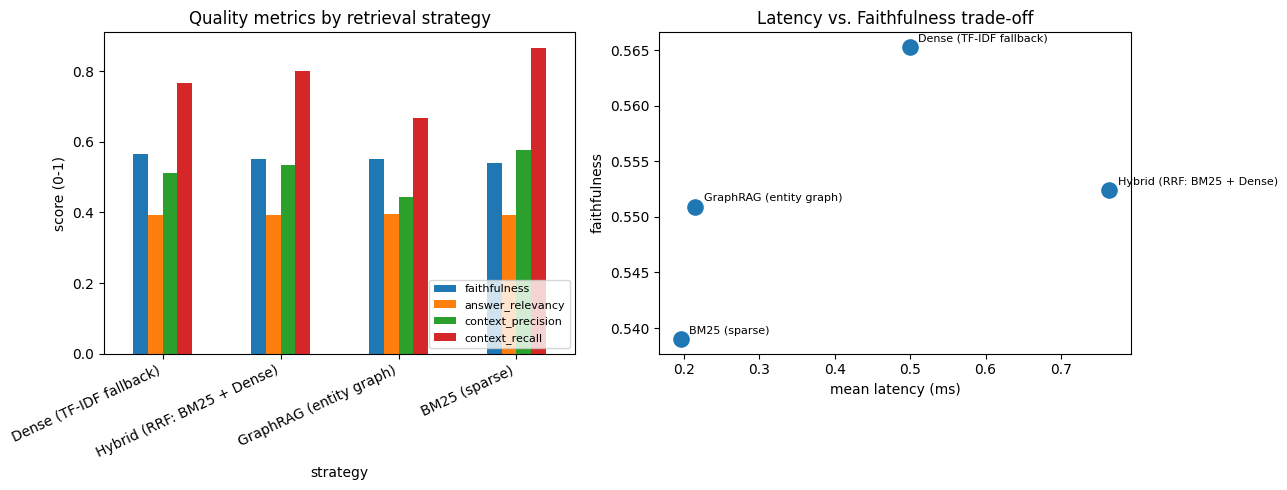

In [11]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metrics_to_plot = ["faithfulness", "answer_relevancy", "context_precision", "context_recall"]
agg[metrics_to_plot].plot(kind="bar", ax=axes[0])
axes[0].set_title("Quality metrics by retrieval strategy")
axes[0].set_ylabel("score (0-1)")
axes[0].set_xticklabels(agg.index, rotation=25, ha="right")
axes[0].legend(loc="lower right", fontsize=8)

axes[1].scatter(agg["latency_mean_ms"], agg["faithfulness"], s=120)
for name, row in agg.iterrows():
    axes[1].annotate(name, (row["latency_mean_ms"], row["faithfulness"]),
                      textcoords="offset points", xytext=(6, 4), fontsize=8)
axes[1].set_xlabel("mean latency (ms)")
axes[1].set_ylabel("faithfulness")
axes[1].set_title("Latency vs. Faithfulness trade-off")

plt.tight_layout()
plt.savefig("rag_eval_report.png", dpi=140)
plt.show()



## 10. Per-question Detail & Export

Inspect individual answers/scores, and export the full results table plus
the summary report for use elsewhere (e.g. a slide, a PR description, a
model card).


In [12]:

pd.set_option("display.max_colwidth", 60)
detail_cols = ["question_id", "strategy_key", "latency_ms", "faithfulness",
                "answer_relevancy", "context_precision", "context_recall", "generated_answer"]
results_df[detail_cols].sort_values(["question_id", "strategy_key"]).head(20)


,question_id,strategy_key,latency_ms,faithfulness,answer_relevancy,context_precision,context_recall,generated_answer
0,q1,bm25,0.182930,0.591599,0.318269,0.666667,1.0,The Eiffel Tower is a wrought-iron lattice tower in Pari...
1,q1,dense,0.562660,0.591599,0.318269,0.666667,1.0,The Eiffel Tower is a wrought-iron lattice tower in Pari...
3,q1,graph,0.187234,0.591599,0.318269,0.666667,1.0,The Eiffel Tower is a wrought-iron lattice tower in Pari...
2,q1,hybrid,0.691033,0.591599,0.318269,0.666667,1.0,The Eiffel Tower is a wrought-iron lattice tower in Pari...
36,q10,bm25,0.186990,0.377248,0.356300,0.333333,0.5,Its premiere in Paris in 1913 famously caused a near-riot
37,q10,dense,0.445135,0.377248,0.356300,0.333333,0.5,Its premiere in Paris in 1913 famously caused a near-riot
39,q10,graph,0.205058,0.407230,0.356300,0.333333,0.5,Its premiere in Paris in 1913 famously caused a near-riot
38,q10,hybrid,0.778438,0.377248,0.356300,0.333333,0.5,Its premiere in Paris in 1913 famously caused a near-riot
40,q11,bm25,0.174534,0.622653,0.443002,0.666667,1.0,Mount Kilimanjaro is the highest mountain in Africa
41,q11,dense,0.425971,0.622653,0.443002,0.666667,1.0,Mount Kilimanjaro is the highest mountain in Africa


In [13]:

results_df.to_csv("rag_eval_results_full.csv", index=False)
agg.to_csv("rag_eval_results_summary.csv")
print("Wrote rag_eval_results_full.csv, rag_eval_results_summary.csv, rag_eval_report.png")


Wrote rag_eval_results_full.csv, rag_eval_results_summary.csv, rag_eval_report.png



## 11. Notes, Caveats & How to Get Full-Fidelity Numbers

- **This run's mode summary** is printed above Section 9's table
  (`data source`, `answers mode`, `metrics mode`) — always check it before
  trusting absolute numbers; only "real RAGAS" + a real LLM + real HotpotQA
  data reflect production-representative results.
- **Swap in Natural Questions**: replace the `load_dataset(...)` call in
  Section 3 with `load_dataset("natural_questions", split="validation[:50]")`
  and adjust field names (NQ's schema differs slightly from HotpotQA's —
  it has `document.tokens` + `long_answer_candidates` rather than
  `context`/`supporting_facts`).
- **Real vector DB**: swap `faiss.IndexFlatIP` in `DenseRetriever` for a
  `Pinecone`/`Weaviate` client with the same `.search()`-style interface —
  the rest of the harness doesn't care where the index lives.
- **Real Neo4j GraphRAG**: set `NEO4J_URI`, `NEO4J_USER`, `NEO4J_PASSWORD`
  env vars before instantiating `GraphRAGRetriever`; it will auto-detect
  and mirror the graph into Neo4j, querying via Cypher instead of NetworkX.
- **Scale up**: increase `N_SAMPLES` in Section 3 and `K` (top-k) in
  Section 8 for a more statistically meaningful benchmark — 15 questions
  is a smoke-test size, not a paper-grade sample.
- **Cost control**: LLM answer generation + real RAGAS both call an LLM
  API per question per strategy (`4 strategies x N questions x ~2 calls`)
  — budget accordingly for larger `N_SAMPLES`.
